# Projet DVF : prix au m² (Ain, 2022-2025)
**Étape 1 : chargement, nettoyage, agrégation par mutation, cible `prix_m2`.**

Avant de lancer : place tes 4 fichiers `ValeursFoncieres-2022...2025` dans le dossier `data/` à côté de ce notebook.

In [1]:
import pandas as pd, numpy as np, glob, os
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

DEP = '01'   # département à garder (Ain). Mets None pour tout garder (attention RAM)
FILES = sorted(glob.glob('data/ValeursFoncieres-20*'))
print(FILES)
assert len(FILES) > 0, 'Aucun fichier trouvé : mets tes fichiers dans le dossier data/ du projet'

['data\\ValeursFoncieres-2022.txt', 'data\\ValeursFoncieres-2023.txt', 'data\\ValeursFoncieres-2024.txt', 'data\\ValeursFoncieres-2025.txt']


## 1. Chargement (par morceaux, filtre département dès la lecture)

In [2]:
USECOLS = ['No disposition','Date mutation','Nature mutation','Valeur fonciere',
           'No voie','Type de voie','Voie','Code postal','Commune',
           'Code departement','Code commune','Section','No plan',
           '1er lot','Surface Carrez du 1er lot','2eme lot','Surface Carrez du 2eme lot',
           '3eme lot','Surface Carrez du 3eme lot','4eme lot','Surface Carrez du 4eme lot',
           '5eme lot','Surface Carrez du 5eme lot','Nombre de lots',
           'Code type local','Type local','Surface reelle bati','Nombre pieces principales',
           'Nature culture','Nature culture speciale','Surface terrain']

def lire(path):
    for enc in ('utf-8', 'latin-1'):
        try:
            parts = []
            for ch in pd.read_csv(path, sep='|', usecols=USECOLS, dtype=str,
                                  chunksize=200_000, encoding=enc, on_bad_lines='skip'):
                if DEP is not None:
                    ch = ch[ch['Code departement'] == DEP]
                parts.append(ch)
            return pd.concat(parts, ignore_index=True)
        except UnicodeDecodeError:
            continue
    raise ValueError(f'Encodage non reconnu pour {path}')

dfs = []
for f in FILES:
    d = lire(f)
    d['fichier'] = os.path.basename(f)
    print(f'{os.path.basename(f)} : {len(d):,} lignes')
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
del dfs
print('Total brut :', f'{len(df):,}')

ValeursFoncieres-2022.txt : 51,620 lignes
ValeursFoncieres-2023.txt : 44,657 lignes
ValeursFoncieres-2024.txt : 39,958 lignes
ValeursFoncieres-2025.txt : 42,383 lignes
Total brut : 178,618


## 2. Conversion des types

In [3]:
CARREZ = [c for c in df.columns if c.startswith('Surface Carrez')]
NUM = ['Valeur fonciere','Surface reelle bati','Nombre pieces principales','Surface terrain'] + CARREZ
for c in NUM:
    df[c] = pd.to_numeric(df[c].str.replace(',', '.', regex=False), errors='coerce')

df['Date mutation'] = pd.to_datetime(df['Date mutation'], format='%d/%m/%Y', errors='coerce')
df['Code postal'] = df['Code postal'].str.zfill(5)
df['insee'] = df['Code departement'] + df['Code commune'].str.zfill(3)   # clé pour jointures externes

# identifiant de mutation (une vente = plusieurs lignes)
df['mut_id'] = (df['Date mutation'].dt.strftime('%Y%m%d') + '_' + df['No disposition'].fillna('') + '_'
                + df['insee'] + '_' + df['Valeur fonciere'].astype(str))

df = df.dropna(subset=['Date mutation', 'Valeur fonciere'])
funnel = {'lignes brutes': len(df), 'mutations brutes': df['mut_id'].nunique()}

## 3. Filtres de base : ventes simples uniquement

In [4]:
# Exclut échanges, VEFA (neuf), adjudications, expropriations...
df = df[df['Nature mutation'] == 'Vente']
df = df.drop_duplicates()
funnel['mutations de type Vente'] = df['mut_id'].nunique()

# Locaux d'activité/commerce : vente mixte, impossible de séparer le prix -> on exclut la mutation
ids_mixtes = df.loc[df['Type local'].fillna('').str.startswith('Local'), 'mut_id'].unique()
df = df[~df['mut_id'].isin(ids_mixtes)]
funnel['sans local commercial/industriel'] = df['mut_id'].nunique()

## 4. Agrégation : une ligne par mutation
- Le bien principal = Maison ou Appartement, dédoublonné (un même bien apparaît une fois par parcelle/nature de culture).
- On garde uniquement les mutations avec **un seul** bien principal.
- Terrain = somme des sous-parcelles distinctes. Dépendances = information binaire + comptage approximatif.

In [5]:
bati = df[df['Type local'].isin(['Maison', 'Appartement'])]
bati_u = bati.drop_duplicates(subset=['mut_id','Section','No plan','1er lot','Type local',
                                      'Surface reelle bati','Nombre pieces principales'])
nb_bati = bati_u.groupby('mut_id').size()
ids_ok = nb_bati[nb_bati == 1].index
funnel['avec 1 seul bien (maison/appart)'] = len(ids_ok)

principal = bati_u[bati_u['mut_id'].isin(ids_ok)].copy()
principal['surface_carrez'] = principal[CARREZ].sum(axis=1, min_count=1)   # somme des lots Carrez (peut inclure cave)

# terrain : sous-parcelles distinctes
parc = df.drop_duplicates(subset=['mut_id','Section','No plan','Nature culture',
                                  'Nature culture speciale','Surface terrain'])
terrain = parc.groupby('mut_id')['Surface terrain'].sum().rename('surface_terrain')

# dépendances (garage, cave...) : max d'occurrences par sous-parcelle pour éviter le double comptage
dep = df[df['Type local'].fillna('').str.contains('pendance')]
dep_n = (dep.groupby(['mut_id','Section','No plan','Nature culture'], dropna=False).size()
            .groupby('mut_id').max().rename('nb_dependances'))

m = (principal
     .merge(terrain, on='mut_id', how='left')
     .merge(dep_n, on='mut_id', how='left'))
m['nb_dependances'] = m['nb_dependances'].fillna(0).astype(int)
m['a_dependance'] = (m['nb_dependances'] > 0).astype(int)
m['surface_terrain'] = m['surface_terrain'].fillna(0)

m = m.rename(columns={'Valeur fonciere':'valeur_fonciere','Surface reelle bati':'surface_bati',
                      'Nombre pieces principales':'pieces','Type local':'type_local',
                      'Commune':'commune','Code postal':'code_postal','Date mutation':'date'})
print(m.shape)

(31026, 38)


## 5. Cible `prix_m2` et filtres d'outliers

In [6]:
m = m.dropna(subset=['surface_bati', 'pieces'])
m = m[m['surface_bati'] > 0]
m['prix_m2'] = m['valeur_fonciere'] / m['surface_bati']
funnel['avec surface renseignée'] = len(m)

# règles métier (à ajuster après EDA)
regles = (m['valeur_fonciere'].between(15_000, 5_000_000)
          & m['surface_bati'].between(9, 500)
          & m['pieces'].between(1, 12)
          & m['prix_m2'].between(300, 12_000))
print('Lignes retirées par les règles métier :', (~regles).sum())
m = m[regles]
funnel['après filtres outliers'] = len(m)

# filtre statistique par type de bien et par année (1% - 99%)
def garde_quantiles(g, lo=0.01, hi=0.99):
    a, b = g['prix_m2'].quantile([lo, hi])
    return g[g['prix_m2'].between(a, b)]
m['annee'] = m['date'].dt.year
m = m.groupby(['type_local','annee'], group_keys=False)[m.columns].apply(garde_quantiles)
funnel['final'] = len(m)

print(pd.Series(funnel).to_string())

Lignes retirées par les règles métier : 284
lignes brutes                       177114
mutations brutes                     60070
mutations de type Vente              55149
sans local commercial/industriel     51864
avec 1 seul bien (maison/appart)     31026
avec surface renseignée              31026
après filtres outliers               30742
final                                30125


## 6. Variables temporelles et sélection finale

In [7]:
m['mois'] = m['date'].dt.month
m['trimestre'] = m['date'].dt.quarter
m['annee_mois'] = m['date'].dt.to_period('M').astype(str)   # clé pour joindre l'indice Notaires-INSEE / taux de crédit
m['log_surface'] = np.log(m['surface_bati'])
m['section'] = m['insee'] + '_' + m['Section'].fillna('?')   # quartier cadastral

final = m[['date','annee','mois','trimestre','annee_mois','insee','commune','code_postal','section',
           'type_local','surface_bati','surface_carrez','pieces','surface_terrain',
           'nb_dependances','a_dependance','log_surface','valeur_fonciere','prix_m2']].reset_index(drop=True)
final.head()

,date,annee,mois,trimestre,annee_mois,insee,commune,code_postal,section,type_local,surface_bati,surface_carrez,pieces,surface_terrain,nb_dependances,a_dependance,log_surface,valeur_fonciere,prix_m2
0,2022-01-03,2022,1,1,2022-01,01053,BOURG-EN-BRESSE,01000,01053_AM,Appartement,24.0,24.10,1.0,0.0,0,0,3.178054,55000.0,2291.666667
1,2022-01-03,2022,1,1,2022-01,01398,SAVIGNEUX,01480,01398_ZE,Appartement,140.0,123.23,3.0,172.0,0,0,4.941642,143000.0,1021.428571
2,2022-01-04,2022,1,1,2022-01,01053,BOURG-EN-BRESSE,01000,01053_CS,Appartement,46.0,70.02,1.0,0.0,1,1,3.828641,134000.0,2913.043478
3,2022-01-04,2022,1,1,2022-01,01004,AMBERIEU-EN-BUGEY,01500,01004_AN,Appartement,67.0,69.98,4.0,0.0,3,1,4.204693,138000.0,2059.701493
4,2022-01-05,2022,1,1,2022-01,01419,THOIRY,01710,01419_BN,Appartement,39.0,39.73,2.0,0.0,1,1,3.663562,176000.0,4512.820513


## 7. Vérifications rapides

In [8]:
print(pd.crosstab(final['annee'], final['mois']))
print()
print(final.groupby(['annee','type_local'])['prix_m2'].agg(['count','median','mean','std']).round(0))
print()
print('Communes avec < 10 ventes :', (final['commune'].value_counts() < 10).sum(), '/', final['commune'].nunique())
print()
print(final.isna().mean().round(3))

mois    1    2    3    4    5    6     7    8    9    10   11   12
annee                                                             
2022   605  598  782  667  709  848  1096  604  843  667  667  818
2023   591  534  676  545  573  739   796  450  650  603  452  549
2024   439  465  414  439  476  581   789  477  615  572  466  682
2025   487  494  637  579  478  680   883  503  721  689  543  954

                   count  median    mean     std
annee type_local                                
2022  Appartement   3161  2635.0  2969.0  1365.0
      Maison        5743  2610.0  2811.0  1267.0
2023  Appartement   2672  2614.0  2990.0  1404.0
      Maison        4486  2576.0  2790.0  1289.0
2024  Appartement   2328  2557.0  2999.0  1502.0
      Maison        4087  2500.0  2699.0  1244.0
2025  Appartement   2768  2696.0  3142.0  1535.0
      Maison        4880  2517.0  2709.0  1208.0

Communes avec < 10 ventes : 47 / 394

date               0.000
annee              0.000
mois              

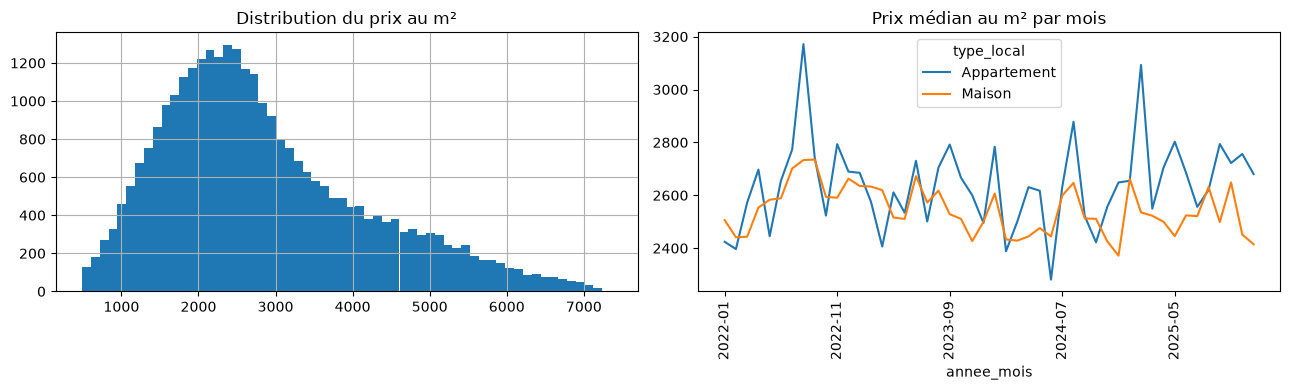

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
final['prix_m2'].hist(bins=60, ax=ax[0]); ax[0].set_title('Distribution du prix au m²')
final.groupby(['annee_mois','type_local'])['prix_m2'].median().unstack().plot(ax=ax[1], rot=90)
ax[1].set_title('Prix médian au m² par mois')
plt.tight_layout(); plt.show()

## 8. Sauvegarde

In [10]:
os.makedirs('data', exist_ok=True)
final.to_parquet('data/dvf_clean.parquet', index=False)
final.to_csv('data/dvf_clean.csv', index=False)
print('Sauvegardé dans data/dvf_clean.parquet')

Sauvegardé dans data/dvf_clean.parquet


## Prochaines étapes
1. Jointure externe via `insee` et `annee_mois` (indice des prix des logements, taux de crédit, population, revenus, distance à Genève).
2. Split temporel : entraînement 2022-2024, test 2025.
3. Baseline médiane par commune, puis Ridge, LightGBM, CatBoost.
4. Courbe d'apprentissage et intervalles de prédiction.